**Author**: JW Debelius (justine.debelius@jhu.edu)<br>
**Project**: 017-Arg<br>
**Enviroment**: <br>
**Creation Date**: July 2021<br>
**Update Date**: November 2025

This notebook will look at the integrated metadata for the project, and build a consort diagram and series of heatmaps to show where samples were dropped out.

In [1]:
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sn

import scripts.time_grid as tg

np.set_printoptions(precision=5)
%matplotlib inline

# Reference data

We start by pulling in the clean reference metadata for hte project which contains all the samples. We're specifically interested in 

In [2]:
md_sam = pd.read_csv('final-data/01.metadata/all_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
md_sam.set_index('sample-id', inplace=True)

In [3]:
md_final = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
md_final.set_index('sample-id', inplace=True)

# Sample dropound

We'll start by building a frame that lets us track where samples and timepoints are.

In [4]:
# Pivots wider so tehre's a space for every timepoint
sampled = md_sam.reset_index().pivot(index=['abx_code2', 'host_subject_id'], 
                                     columns='timepoint',
                                     values='sample-id')
# Replaces missing sample IDs in the while count timepoint as "ns"
# There are some backup samples denoted with a 0.5 adjustemnet off the
# timepoint; we do not incldue the 'ns' code there
sampled.replace({f'{i}.0': {np.nan: 'ns'} for i in np.arange(7)},
                inplace=True)


And then we'll define the steps where samples are dropped

In [5]:
# Converts the data back to a long form
track = sampled.reset_index().melt(id_vars=['abx_code2', 'host_subject_id'],
                                   value_name='sample-id',
                                   var_name='timepoint')
track.dropna(subset=['sample-id'], inplace=True)
track.sort_values(['abx_code2', 'host_subject_id', 'timepoint'], 
                  ascending=True, 
                  inplace=True)
track.reset_index(drop=True, inplace=True)

track['start'] = False

# Samples not collected
track['nc'] = track['sample-id'].isin(['ns'])

# Sample not extracted
track['ne'] = track['sample-id'].replace(md_sam['extraction_no']).isin(['not extracted'])

# Sample not sequenced
track['ns'] = track['sample-id'].replace(md_sam['sequencer_id'])
track['ns'] = track['ns'].isin(['not sequenced'])

# Samples with fewer than 1M reads in the final table
track['deep'] = \
    track['sample-id'].replace(md_sam['gtdb_depth']).replace({"ns": np.nan})
track['deep'] = track['deep'].astype(float) < 1e6

# Exploration showed two samples were mislabled as controls
track['ml'] = track['sample-id'].isin(['17-608', '17-064'])

# Replicated sample (collected off cycle)
track['off'] = track['timepoint'].isin(['3.5', '4.5'])

# Sample collected after antibiotics
# A negative value in the `days_since_last_abx` indicates that samples were
# collected before a second antibiotic dose. So, we'll code everyone who
# didn't take a second antibiotic as 365 days before the second anitbiotic 
# And then set the filter based on that timing
track['abx'] = \
    track['sample-id'].replace(md_sam['days_since_last_abx'])
track.replace({'abx': {"control": '-365', np.nan: '-365', 'ns': '-365'}},
              inplace=True)
track['abx'] = track['abx'].astype(float) >= 0

# We has some issue with extraction 7, so we're going to exclude samples
# that were split between plate 6 and plate 7 to avoid these strong batch
# effects
track['extr'] = \
    track['sample-id'].replace(md_sam['extraction_no']).isin(['Extraction 7']) & \
    (track['host_subject_id'].isin(['1071']))

# We drop samples where the sample from the first participant is missing
# so I want to take the first calculation
track_first = \
    track.groupby('host_subject_id')[['nc', 'ne', 'ns', 'deep', 'ml', 'extr']].first()

# Preps the frame for tracking with teh samples ordered correctly
# For the ordering, we'll have the samples removed by the step first and then
# the samples that are dropped when we lose the baseline sample
track.set_index(['abx_code2', 'host_subject_id', 'timepoint', 'sample-id'],
                inplace=True)

And we'll code each of these based on whether the sample is dropped because its the first sample (code 3), the sample is dropped because it meets the criteria (code 2), or the sample is dropped becuase the participant is dropped (code 1). By using a log model here, we can more easily classify combinations. (Score one for logs)

In [6]:
track2 = track.copy().reset_index()
track2['start_code'] = 0
track2['first_sample'] = track2['timepoint'].isin(['0.0', 0])
track2['later_sample'] = ~track2['first_sample']
track2['nc_code'] = \
    track2[['nc', 'first_sample']].all(axis=1) * 8 + \
    track2[['nc', 'later_sample']].all(axis=1) * 4 + \
    track_first.loc[track2['host_subject_id'], 'nc'].values * 2
track2['ne_code'] = \
    track2[['ne', 'first_sample']].all(axis=1) * 8 + \
    track2[['ne', 'later_sample']].all(axis=1) * 4 + \
    track_first.loc[track2['host_subject_id'], 'ne'].values * 2
track2['ns_code'] = \
    track2[['ns', 'first_sample']].all(axis=1) * 8 + \
    track2[['ns', 'later_sample']].all(axis=1) * 4 + \
    track_first.loc[track2['host_subject_id'], 'ns'].values * 2
track2['deep_code'] = \
    track2[['deep', 'first_sample']].all(axis=1) * 8 + \
    track2[['deep', 'later_sample']].all(axis=1) * 4 + \
    track_first.loc[track2['host_subject_id'], 'deep'].values * 2
track2['ml_code'] = \
    track2[['ml', 'first_sample']].all(axis=1) * 8 + \
    track2[['ml', 'later_sample']].all(axis=1) * 4 + \
    track_first.loc[track2['host_subject_id'], 'ml'].values * 2
track2[['off_code', 'abx_code', 'extr_code']] = \
    track2[['off', 'abx', 'extr']] * 2

track3 = \
    track2.set_index(['abx_code2', 'host_subject_id', 'timepoint', 'sample-id']).copy()
track3 = track3[[c for c in track3.columns if (('code' in c))]].copy()
track3 = np.floor(np.log2(track3 + 1)).astype(int)
track3['nc_code'].value_counts()

nc_code
0    596
2     11
1      6
3      1
Name: count, dtype: int64

## Sample Retention

I want to count he number of samples included/excluded at each step. For this to work overall, we need to combine all three types of samples (first, subsequent, and participant dropped) into a single category.

In [7]:
track4 = track3.reset_index().melt(
    id_vars=['abx_code2', 'host_subject_id', 'timepoint', 'sample-id'],
    var_name='step', 
    value_name='step_code')
code_order = {'start_code': '0',
              "nc_code": '1', 'ne_code': '2', 'ns_code': '3', 
              'deep_code': '4', 'ml_code': '5', 'off_code': '6',
              'abx_code': '7', 'extr_code': '8'}
track4['step_order'] = track4['step'].replace(code_order).astype(str)
track4['part_drop'] = (track4['step_code'] == 3) * 1
track4['samp_drop'] = (track4['step_code'] > 0) * 1
track4[['part_drop', 'samp_drop']] = \
    track4.groupby(['abx_code2', 'host_subject_id', 'timepoint', 'sample-id'])[['part_drop', 'samp_drop']].cummax()
track4['keep_part'] = ((track4['part_drop'] == 0) & track4['timepoint'].isin([0, '0.0'])) * 1
track4['keep_sample'] = (track4['samp_drop'] == 0) * 1

In [8]:
keep_counts = \
    track4.groupby(['step_order', 'step'])[['keep_part', 'keep_sample']].sum()
keep_counts

,,keep_part,keep_sample
step_order,step,,
0,start_code,87,614
1,nc_code,86,596
2,ne_code,86,595
3,ns_code,80,549
4,deep_code,75,496
5,ml_code,74,489
6,off_code,74,486
7,abx_code,74,476
8,extr_code,74,473


## Sample Exclusion

For the sample exclusion, I'd like to be able to classify samples as excluded at each step because they failed the critiera vs because the participant was excluded due to a loss of baseline samples. We're going to identify the step where samples were lost based on the 

In [9]:
excl_track = pd.DataFrame({'sample_track': (track * np.arange(9, 0, -1)).max(axis=1)})
excl_track['part_drop_track'] = excl_track.index.to_frame()['host_subject_id']
excl_track.replace(
    {'part_drop_track': excl_track.groupby('host_subject_id')['sample_track'].first().astype(str)},
    inplace=True)
excl_track = excl_track.astype(float)
excl_track['part_drop'] = excl_track['sample_track'].mask(
    ~excl_track.index.to_frame()['timepoint'].isin(['0.0']))
excl_track['sample_drop'] = \
    excl_track[['sample_track', 'part_drop_track']].max(axis=1)
excl_track['sample_drop'] = \
    ((excl_track['sample_drop'] == excl_track['part_drop_track']) &
     (excl_track['sample_drop'] != 0)) * 0.5 + excl_track['sample_drop']

In [10]:
drops = pd.DataFrame({'samples': excl_track['sample_drop'].value_counts(),})
drops.index.set_names('step_c', inplace=True)
drops.reset_index(inplace=True)
drops['step'] = np.floor(drops['step_c'])
drops['with_part'] = (drops['step_c'] != np.floor(drops['step_c'])) * 1

drops = \
    drops.pivot(index='step', columns='with_part', values='samples')
drops.rename(columns={0: 'addit', 1: 'with_bl'}, inplace=True)
drops['participants'] = excl_track['part_drop'].value_counts()
drops = drops.fillna(0).astype(int)
drops.drop(index=[0], inplace=True)
drops.index = 8 - drops.index
drops['step'] = {0: 'Not collected',
                 1: 'Not extracted',
                 2: 'Not sequenced',
                 3: '<1M reads',
                 4: 'Mislabeled control',
                 5: 'Duplicate timepoint',
                 6: 'After antibiotics',
                 7: 'Split across 6 and 7'}

def _tidy_drops(x):
    add = x['addit']
    part = x['participants']
    with_bl = x['with_bl']
    if (part > 0) and (add > 0):
        return f'{part} subjects ({with_bl} samples)\n{add} samples'
    elif (part > 0):
        return f'{part} subjects ({with_bl} samples)'
    else:
        return f'{add} samples'
drops['tidy_str'] = drops.apply(_tidy_drops, axis=1)
drops.index.set_names('step_order', inplace=True)

In [11]:
drops

with_part,addit,with_bl,participants,step,tidy_str
step_order,,,,,
7.0,3,0,0,Split across 6 and 7,3 samples
6.0,10,0,0,After antibiotics,10 samples
5.0,3,0,0,Duplicate timepoint,3 samples
4.0,0,7,1,Mislabeled control,1 subjects (7 samples)
3.0,23,30,5,<1M reads,5 subjects (30 samples)\n23 samples
2.0,4,42,6,Not sequenced,6 subjects (42 samples)\n4 samples
1.0,1,0,0,Not extracted,1 samples
0.0,11,7,1,Not collected,1 subjects (7 samples)\n11 samples


# Build sample consort

In [12]:
consort_k_count = keep_counts.reset_index()
full_step_names = {'start_code': 'Enrolled study population',
                   'nc_code': "Collected samples",
                   'ne_code': "Extracted samples",
                   'ns_code': 'Sequenced samples',
                   'deep_code': 'Samples with at least 1M reads',
                   'ml_code': 'Correctly labeled samples',
                   'off_code': 'Samples collected at unique timepoints',
                   'abx_code': 'Samples collected after antibiotics',
                   'extr_code': 'Final analytical sample'}

consort_k_count['step_name'] = consort_k_count['step'].replace(full_step_names)
consort_k_count['tidy_name'] = \
    consort_k_count[['keep_part', 'keep_sample']].apply(
        lambda x: '{0} subjects; {1} samples'.format(*x), axis=1)

In [13]:
consort_k_count2 = consort_k_count.loc[
    ~consort_k_count['step'].isin(['ne_code', 'deep_code', 'off_code', 'abx_code'])
    ].copy()
consort_k_count2.reset_index(inplace=True, drop=True)
consort_k_count2['next_step'] = (consort_k_count2['step_order'].shift(-1)).astype(float)
consort_k_count2.loc[0, 'tidy_name'] = '87 subjects; 609 samples + 5 replicates'

In [14]:
step_markers = {0: 'X',
                1: '$E$',
                2: 'd',
                3: 'v',
                4: '<',
                5: '+',
                6: '*',
                7: '3'}

In [15]:
fig = plt.figure(dpi=150, constrained_layout=True, figsize=(3, 5), facecolor='c')
def plot_drops(fig):
    """
    Wrapper function to build dropouts
    """
    ax = fig.add_subplot(1,1,1, facecolor='None')
    ax.set_position((0, 0, 1, 1))
    for idx, step_df in consort_k_count2.iterrows():
        tg._build_step_wrap(ax=ax, idx=idx, 
                            step=idx, 
                            step_name=step_df['step_name'], 
                            tidy=step_df['tidy_name'], 
                            stop=np.isnan(step_df['next_step'])
                           )
        if ~np.isnan(step_df['next_step']):
            start_stop = np.arange(*step_df[['step_order', 'next_step']].astype(float))
            s_drops = drops.loc[start_stop]
            num_drop = len(s_drops)
            enter_off = 0
            for i, (dstep, [reason, counts]) in \
                    enumerate(s_drops[['step', 'tidy_str']].iterrows()):
                yy = 7.5 - 0.025 - idx - i * 0.125 - enter_off
                ax.text(x=0.225, y=yy, s=reason,
                        size=8, ha='left',  va='top')
                ax.text(x=0.925, y=yy, s=counts,
                        size=8, ha='right', va='top')
                ax.scatter(x=0.20, y=yy - 0.04, 
                           marker=step_markers[dstep], 
                           color='k')
                enter_off += ('\n' in counts) * 0.09
            yr = np.array([0, -(num_drop + 1) * 0.11 - enter_off]) + 7.5 - idx
            ax.fill_between([0.165, 0.95], *yr, color='#dbdbdb', zorder=0)
            ax.plot([0.1, 0.15], [np.mean(yr)] * 2, 'k-', linewidth=3)
            ax.scatter(0.145, np.mean(yr), marker='>', color='k', s=60)
    # 
    #         # ax.scatter(
    ax.xaxis.set_tick_params(**tg.hide_axes)
    ax.yaxis.set_tick_params(**tg.hide_axes)
    ax.set_xlim(0, 1)
    ax.set_ylim(3.5, 8.15)
    sn.despine(ax=ax, left=True, right=True, top=True, bottom=True)

<Figure size 450x750 with 0 Axes>

In [16]:
excl_track.loc[excl_track['sample_drop'] == 7]

,,,,sample_track,part_drop_track,part_drop,sample_drop
abx_code2,host_subject_id,timepoint,sample-id,,,,
5,1047,4.5,18-107,7.0,0.0,NaN,7.0


In [17]:
track_drop = excl_track.drop(index=['3.5', '4.5'],
                             level='timepoint').copy()
track_drop['part_drop'] = track_drop.groupby('host_subject_id')['part_drop'].ffill()
track_drop['is_follow'] = \
    (track_drop['sample_drop'] != np.floor(track_drop['sample_drop'])) * 1
track_drop['drop_step'] = np.floor(track_drop['sample_drop'])
drop_count = track_drop.groupby('host_subject_id')['sample_drop'].apply(
    lambda x: (x > 0).sum()).astype(str)
track_drop['drop_count'] = \
    track_drop.index.to_frame()['host_subject_id'].replace(drop_count)
track_drop['drop_count']  = track_drop['drop_count'].astype(float).astype(int)

track_drop['y'] = track_drop.index.to_frame()['timepoint'].astype(float).astype(int)
track_drop['marker'] = (8 - track_drop['drop_step']).replace(step_markers)
track_drop.replace({'marker': {'8.0': '.', 8: '.', np.nan: '$$E$$'}}, 
                    inplace=True)
track_drop['s'] = ((track_drop['drop_step'] > 0) * 16 + 8).astype(int)
track_drop['color'] = 'k'
track_drop['facecolor'] = \
    track_drop['color'].mask((track_drop['is_follow'] == 1) & (track_drop['y'] > 0), 'w')

track_drop.set_index(['part_drop', 'drop_count', 'drop_step'], 
                     append=True, 
                     inplace=True)
track_drop.sort_index(
    level=['abx_code2', 'drop_count', 'part_drop',
           'host_subject_id', 'timepoint'],
    ascending=[True, False, False, True, True],
    inplace=True)
track_drop['x'] = ((track_drop['y'] == 0) * 1).mask(track_drop['y'] != 0)
track_drop['x'] = track_drop.groupby(['abx_code2'])['x'].cumsum() - 1
track_drop['x'] = track_drop.groupby('host_subject_id')['x'].ffill()
track_drop2 = track_drop[['y', 'x', 's', 'marker', 'color', 'facecolor']].copy()
track_drop2.reset_index(['part_drop'],
                        inplace=True,
                        drop=True)
track_drop2.reset_index('timepoint', inplace=True)
track_drop2[['timepoint', 'x']] = track_drop2[['timepoint', 'x']].astype(float).astype(int)

In [18]:
track_drop2.to_csv('final-data/01.metadata/track_all_samples.tsv',
                   sep='\t')

In [19]:
track_drop2.xs('18-187', level='sample-id')

,,,,timepoint,y,x,s,marker,color,facecolor
abx_code2,host_subject_id,drop_count,drop_step,,,,,,,
3,1090,0,0.0,4,4,14,8,.,k,k


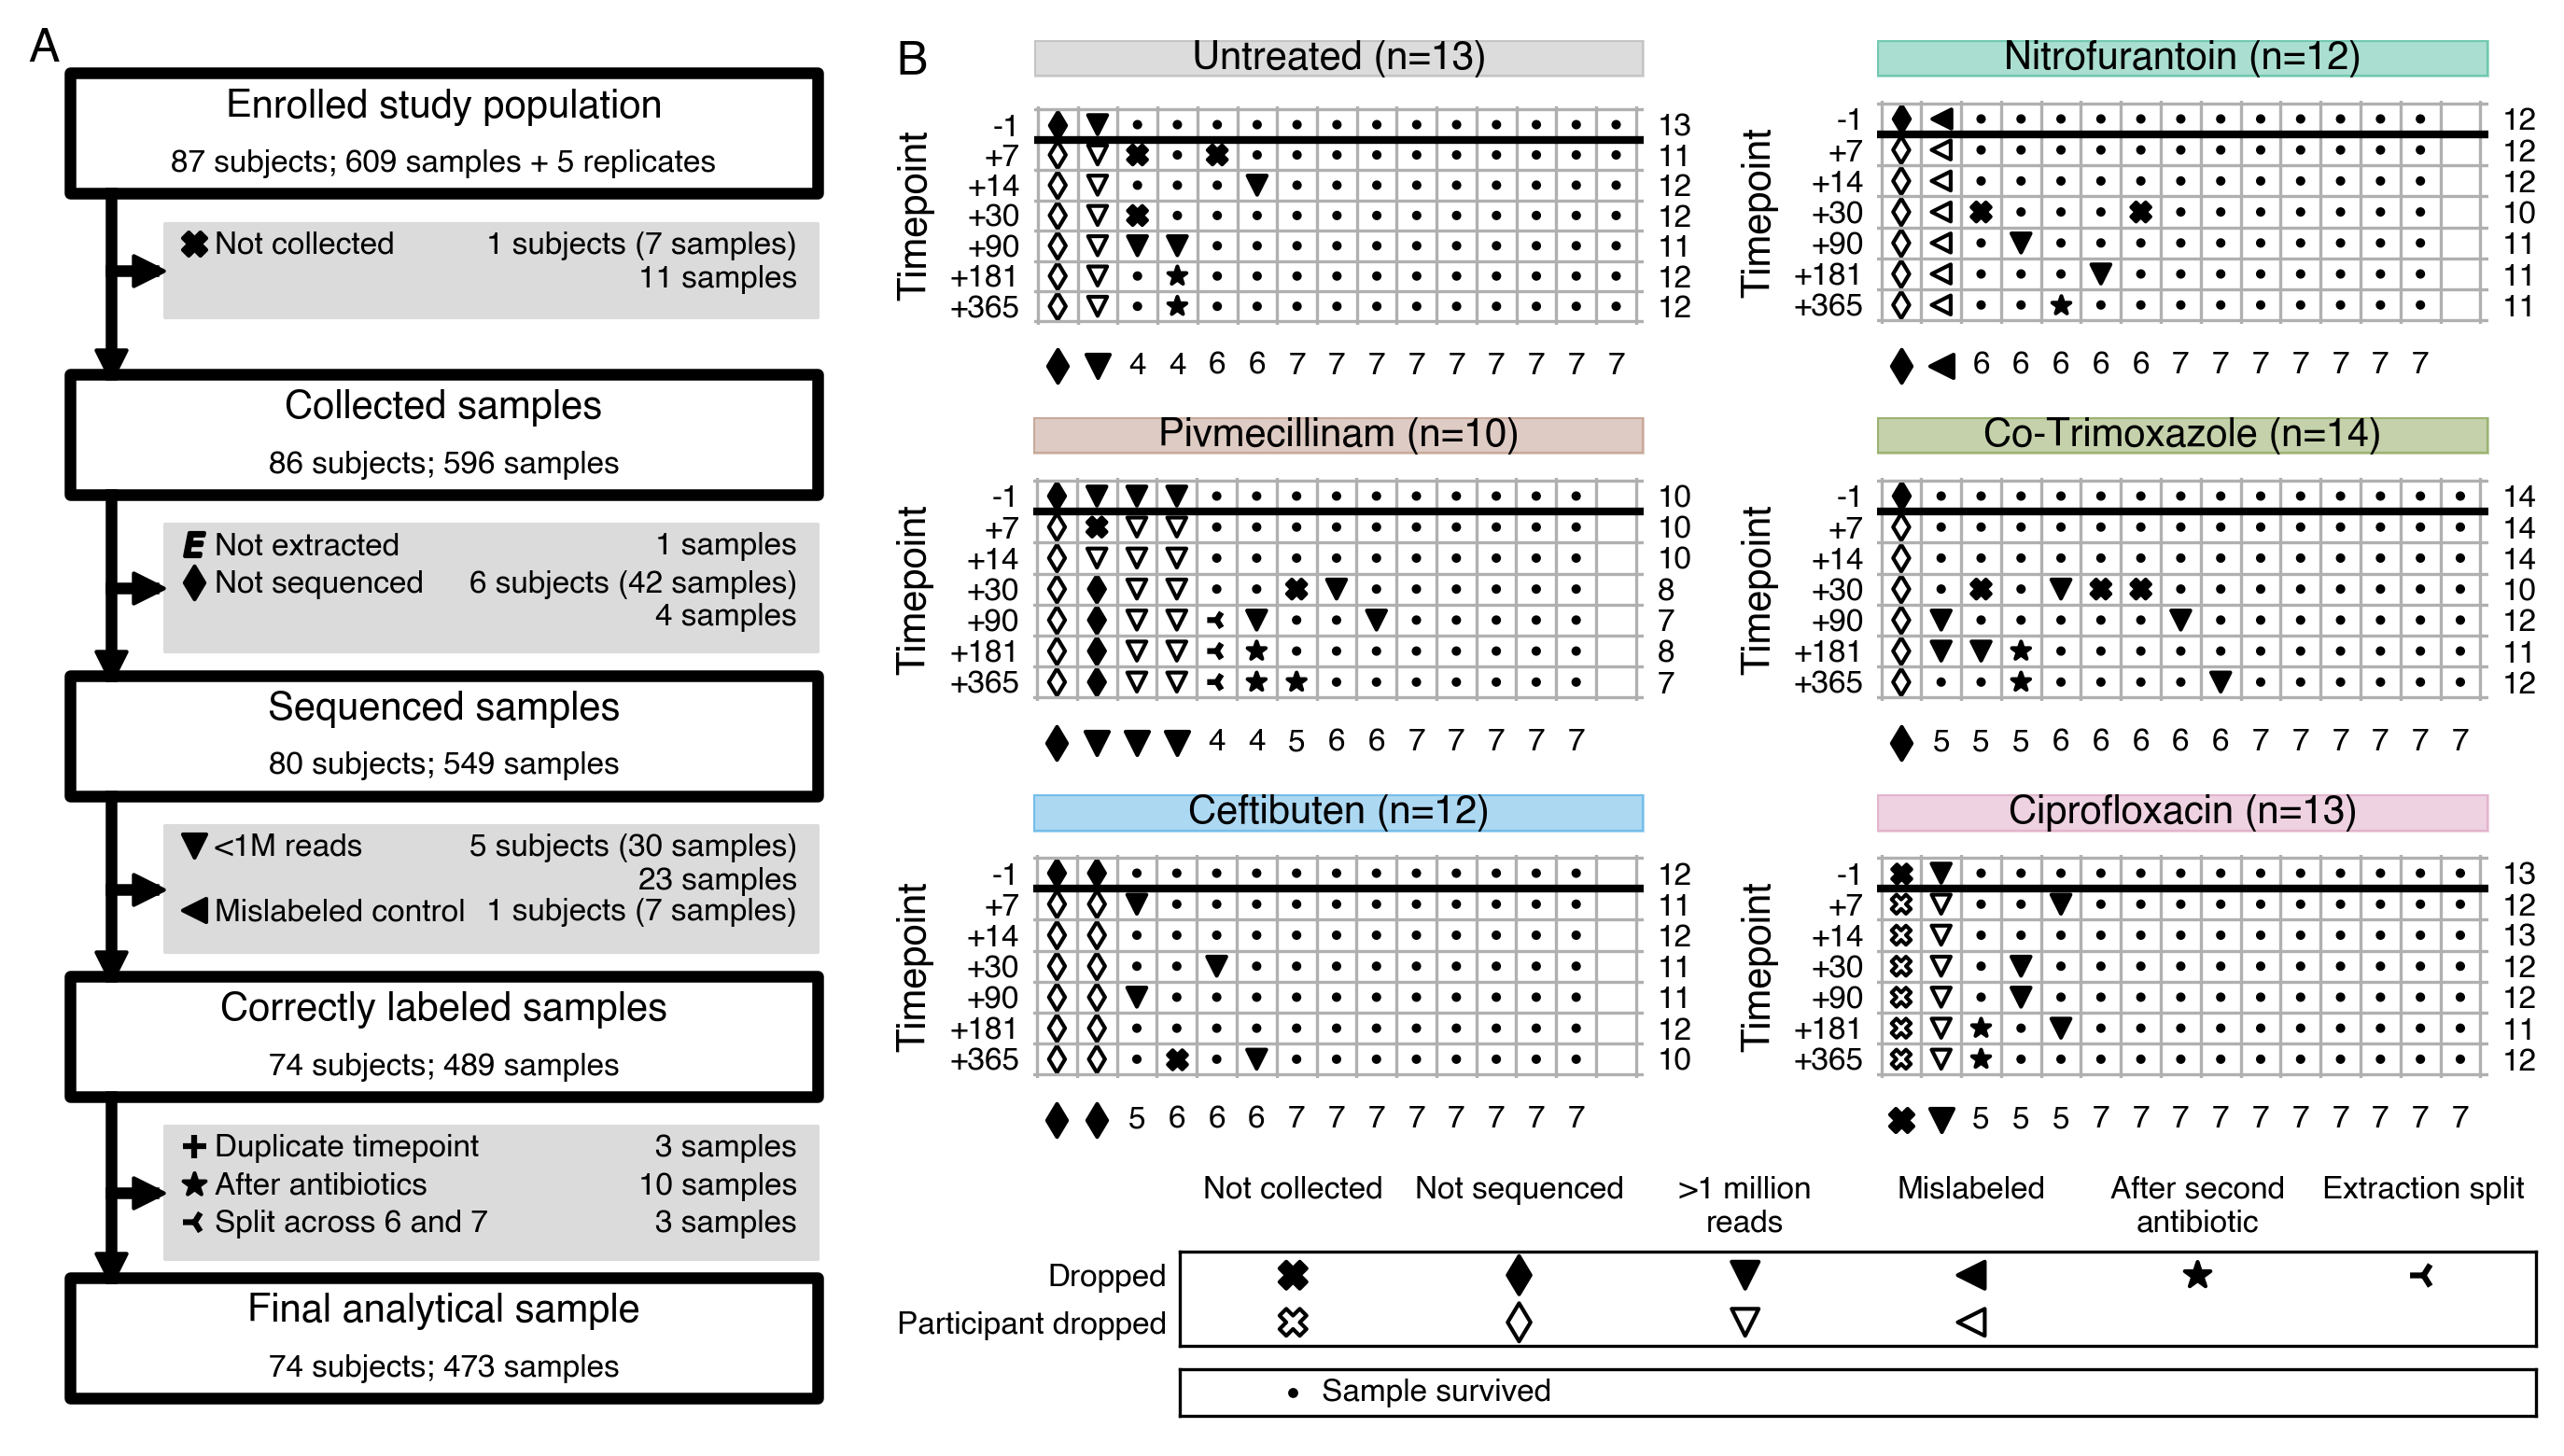

In [20]:
fig = plt.figure(dpi=300, constrained_layout=True, figsize=(9, 5), facecolor='w')
figl, figr = fig.subfigures(1, 2, width_ratios=[1, 2], facecolor='None')
plot_drops(figl)
figl.axes[0].text(figl.axes[0].get_xlim()[0] + 0.0 * np.diff(figl.axes[0].get_xlim()),
                  figl.axes[0].get_ylim()[1] - 0.0 * np.diff(figl.axes[0].get_ylim()),
                  'A',
                  size=12, ha='left', va='top')
figrm, figrl = figr.subfigures(2, 1, height_ratios=[4.25, 1], facecolor='None')
fig_abx = np.hstack(figrm.subfigures(3, 2,  facecolor='None'))
for fig_x, (abx, abx_df) in zip(*(fig_abx,  track_drop2.groupby('abx_code2'))):
    tg.build_drop_grid(fig_x, abx, abx_df)
fig_abx[0].axes[0].text(fig_abx[0].axes[0].get_xlim()[0] - 0.225 * np.diff(fig_abx[0].axes[0].get_xlim()),
                        fig_abx[0].axes[0].get_ylim()[1],
                        'B', size=12, ha='left', va='top')
tg.build_grid_legend(figrl)

In [21]:
os.makedirs('output/figures/', exist_ok=True)
fig.savefig('output/figures/figure_s2_sample_keep.png', dpi=300, facecolor='None')
fig.savefig('output/figures/figure_s2_sample_keep.pdf', dpi=300, facecolor='None')

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped
